In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load both datasets
fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

In [4]:
# Assign labels
fake["label"] = 1
true["label"] = 0

In [5]:
# Combine both datasets
data = pd.concat([fake, true], ignore_index=True)

In [8]:
data.shape

(44898, 5)

In [9]:
data.isnull().sum()

title      0
text       0
subject    0
date       0
label      0
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(209)

In [12]:
data.drop_duplicates(inplace=True)

In [13]:
data.shape

(44689, 5)

In [14]:
# Keep the columns required for prediction
data = data[["title", "text", "label"]]

In [15]:
# Remove missing and duplicate records
data = data.dropna(subset=["title", "text"])
data = data.drop_duplicates(subset=["title", "text"])

In [16]:
# Combine headline and article text
data["content"] = (
    data["title"].astype(str) + " " +
    data["text"].astype(str)
)

In [17]:
print(data.head())
print("\nDataset shape:", data.shape)
print("\nClass distribution:")
print(data["label"].value_counts())

                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text  label  \
0  Donald Trump just couldn t wish all Americans ...      1   
1  House Intelligence Committee Chairman Devin Nu...      1   
2  On Friday, it was revealed that former Milwauk...      1   
3  On Christmas day, Donald Trump announced that ...      1   
4  Pope Francis used his annual Christmas Day mes...      1   

                                             content  
0   Donald Trump Sends Out Embarrassing New Year’...  
1   Drunk Bragging Trump Staffer Started Russian ...  
2   Sheriff David Clarke Becomes An Internet Joke...  
3   Trump Is So Obsessed He Even Has Obama’s Name...  
4   Pope 

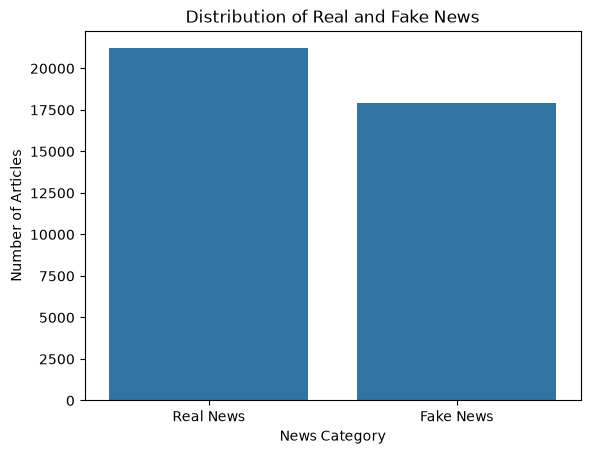

In [18]:
sns.countplot(data=data, x="label")
plt.xticks([0, 1], ["Real News", "Fake News"])
plt.title("Distribution of Real and Fake News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import joblib

In [21]:
# Input and target
X = data["content"]
y = data["label"]

In [22]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [23]:
# Create the complete ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_df=0.7,
        max_features=50000,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

In [24]:
# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [25]:
# Evaluate the model

In [26]:
# Make predictions
y_pred = model.predict(X_test)

In [27]:
model.score(X_train, y_train)

0.9924562076460811

In [28]:
model.score(X_test,y_test)

0.9861910241657077

In [32]:
model.score(X_test,y_pred)

1.0

In [33]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 98.62 %


In [34]:
# Precision, recall, F1-score
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Real News", "Fake News"]
))


Classification Report:
              precision    recall  f1-score   support

   Real News       0.98      0.99      0.99      4239
   Fake News       0.99      0.98      0.98      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



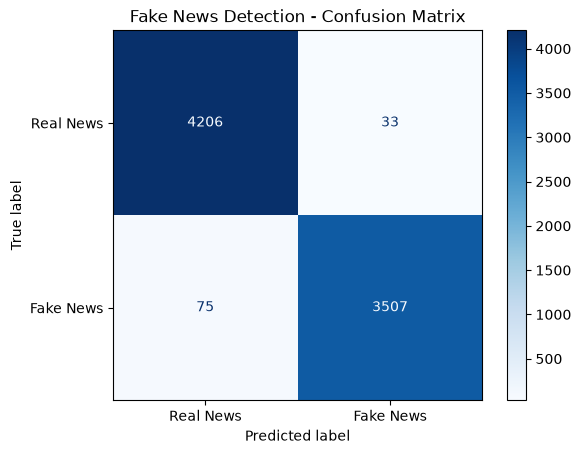

In [35]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real News", "Fake News"]
)

display.plot(cmap="Blues")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()

In [36]:
# Test our own news article

In [38]:
def predict_news(article):
    prediction = model.predict([article])[0]
    probabilities = model.predict_proba([article])[0]

    if prediction == 1:
        result = "Likely Fake News"
        confidence = probabilities[1] * 100
    else:
        result = "Likely Real News"
        confidence = probabilities[0] * 100

    print("Prediction:", result)
    print(f"Model confidence: {confidence:.2f}%")

# Enter a sample article
article = input("Enter a news article or headline: ")
predict_news(article)

Prediction: Likely Fake News
Model confidence: 64.15%


In [39]:
# Save our trained model

In [40]:
joblib.dump(model, "fake_news_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [41]:
model = joblib.load("fake_news_model.pkl")